# 03 · Construction Heuristics

Good routes, instantly. We abandon optimality and build a complete tour from scratch three ways:

- **Nearest-neighbor** — always drive to the closest unvisited stop. Ten lines of code.
- **Clarke-Wright savings** — merge out-and-back legs by how much distance they save.
- **Cheapest insertion** — grow the tour by inserting whichever stop is cheapest to slot in.

We measure each construction's **gap to optimal**: against the exact MILP on a small instance,
and — because the gap grows with size — against a strong best-known reference (a longer OR-Tools
run) across a ladder of larger instances.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from src.evaluation.gap_to_optimal import gap_percent
from src.exact.milp_tsp import milp_tsp
from src.heuristics.christofides_like import cheapest_insertion_tour, savings_tour
from src.heuristics.nearest_neighbor import nearest_neighbor_tour
from src.ortools_solver.routing import solve_tsp
from src.problems.tsp import generate_tsp_instance, tour_length
from src.reporting import save_figure, save_json
from src.visualisation import plot_tour

SEED = 42
TIME_LIMIT = 15.0

CONSTRUCTIONS = {
    "nearest_neighbor": nearest_neighbor_tour,
    "savings": savings_tour,
    "cheapest_insertion": cheapest_insertion_tour,
}

## 1. Four routes for one instance

The exact optimum next to the three constructions on a 12-stop instance, each labelled with its gap to optimal.

In [2]:
N = 12
instance = generate_tsp_instance(N, seed=SEED)
opt_route, opt_length = milp_tsp(instance.distances, time_limit=TIME_LIMIT)

tours = {name: build_tour(instance.distances) for name, build_tour in CONSTRUCTIONS.items()}
summary = {"optimal": {"length": opt_length, "gap_percent": 0.0, "tour": opt_route}}
for name, route in tours.items():
    length = tour_length(route, instance.distances)
    summary[name] = {"length": length, "gap_percent": gap_percent(length, opt_length),
                     "tour": route}
    print(f"{name:>20}: length {length:7.2f}   gap {gap_percent(length, opt_length):5.1f}%")

save_json("03_single_instance", {"stops": N, "seed": SEED, "methods": summary})

    nearest_neighbor: length  380.51   gap  27.7%
             savings: length  298.06   gap   0.0%
  cheapest_insertion: length  298.06   gap   0.0%


PosixPath('/workspaces/routing_arena/outputs/data/03_single_instance.json')

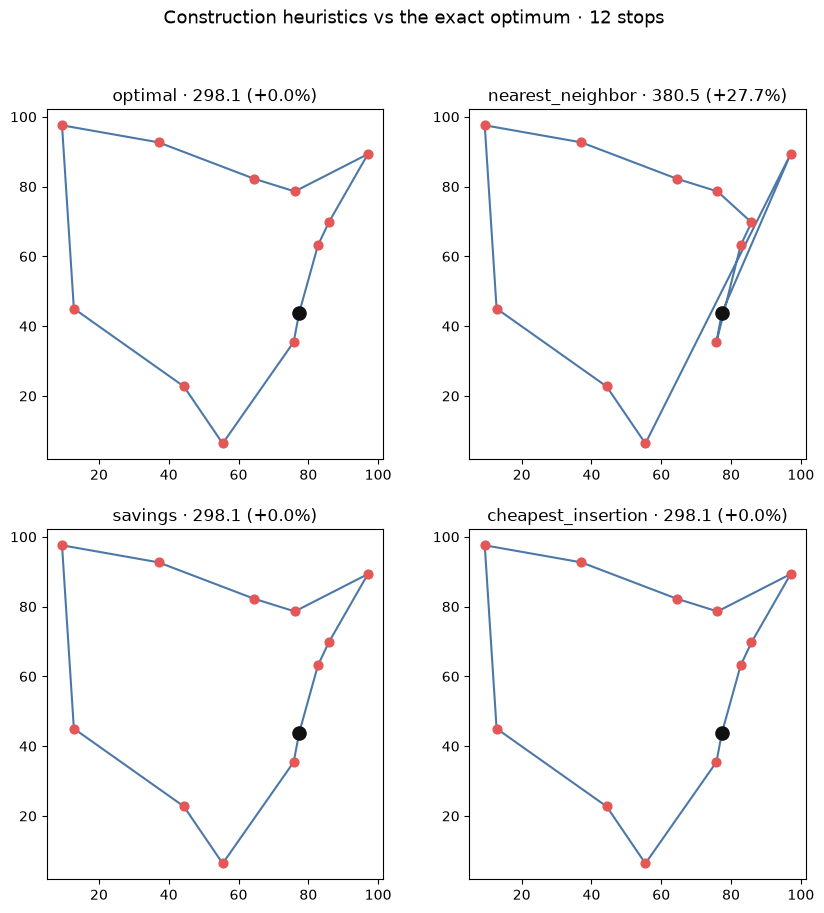

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
panels = [("optimal", opt_route)] + [(name, tours[name]) for name in CONSTRUCTIONS]
for ax, (name, route) in zip(axes.ravel(), panels):
    gap = summary[name]["gap_percent"]
    plot_tour(instance, route, ax=ax, title=f"{name} · {summary[name]['length']:.1f} (+{gap:.1f}%)")
fig.suptitle(f"Construction heuristics vs the exact optimum · {N} stops", fontsize=13)
save_figure(fig, "03_construction_tours")
plt.show()

## 2. The gap grows with size

A single small instance understates it: nearest-neighbor's gap widens as stops are added. We sweep
a size ladder and average over seeds, scoring each construction against a strong best-known
reference (OR-Tools, 3 s). By fifty stops nearest-neighbor sits in its characteristic ~20% band,
while savings and insertion stay much tighter.

In [4]:
ladder = [10, 20, 30, 50]
seeds = [0, 1, 2]
gaps = {name: {n: [] for n in ladder} for name in CONSTRUCTIONS}
for n in ladder:
    for seed in seeds:
        inst = generate_tsp_instance(n, seed=seed)
        _, best_known = solve_tsp(inst.distances, time_limit=3.0)
        for name, build_tour in CONSTRUCTIONS.items():
            g = gap_percent(tour_length(build_tour(inst.distances), inst.distances), best_known)
            gaps[name][n].append(g)

mean_gap = {name: {n: float(np.mean(v)) for n, v in sizes.items()} for name, sizes in gaps.items()}
print("mean gap to best-known (%)")
print(f"{'stops':>6} " + " ".join(f"{name:>18}" for name in CONSTRUCTIONS))
for n in ladder:
    print(f"{n:>6} " + " ".join(f"{mean_gap[name][n]:>18.1f}" for name in CONSTRUCTIONS))

save_json("03_gap_vs_size", {"sizes": ladder, "seeds": seeds, "reference": "ortools_3s_best_known",
                             "mean_gap_percent": mean_gap, "per_seed_gap_percent": gaps})

mean gap to best-known (%)
 stops   nearest_neighbor            savings cheapest_insertion
    10                5.8                0.0               10.9
    20               21.0                2.7                9.4
    30               25.8                5.6               13.3
    50               19.3                5.4               15.3


PosixPath('/workspaces/routing_arena/outputs/data/03_gap_vs_size.json')

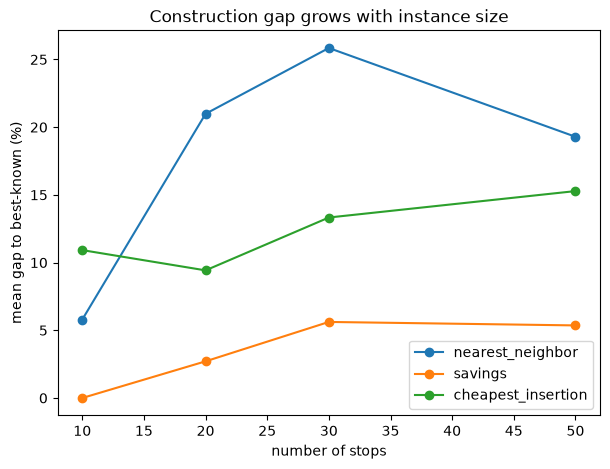

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name in CONSTRUCTIONS:
    ax.plot(ladder, [mean_gap[name][n] for n in ladder], "-o", label=name)
ax.set_xlabel("number of stops")
ax.set_ylabel("mean gap to best-known (%)")
ax.set_title("Construction gap grows with instance size")
ax.legend()
save_figure(fig, "03_gap_vs_size")
plt.show()

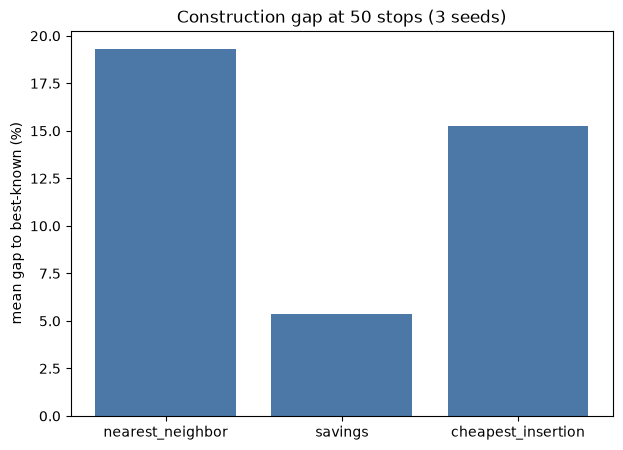

In [6]:
biggest = ladder[-1]
fig, ax = plt.subplots(figsize=(7, 5))
names = list(CONSTRUCTIONS)
ax.bar(names, [mean_gap[name][biggest] for name in names], color="#4C78A8")
ax.set_ylabel("mean gap to best-known (%)")
ax.set_title(f"Construction gap at {biggest} stops ({len(seeds)} seeds)")
save_figure(fig, "03_gap_by_method")
plt.show()

## Takeaway

A complete, usable route is ten lines away, and we now know the price. Nearest-neighbor drifts into
its characteristic ~20-25% band as instances grow — good enough to size a problem, not good enough
to run a fleet on. Savings and insertion start much closer.

Next: **04 · Local Search** — closing most of that remaining gap for almost nothing.